In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

## Case 1: "Premium-certified helmets have 2.5x the head-injury rate"

### 1. Rebuild Code

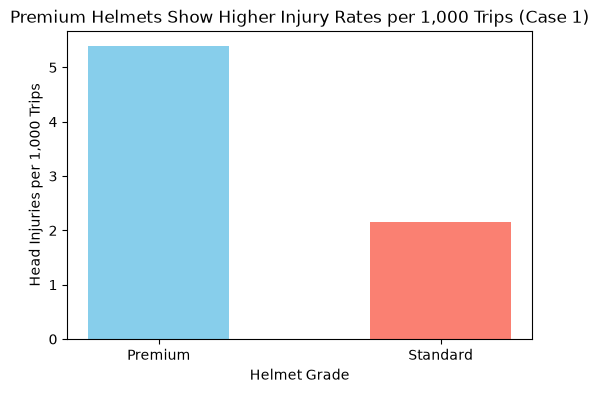

helmet_grade
Premium     5.40
Standard    2.15
Name: injury_rate_per_1000, dtype: float64


In [8]:
# Load dataset with actual columns: rider_id, helmet_grade, road_type, trips, head_injuries, avg_speed_kph, months_experience
df_helmet = pd.read_csv("case01_helmet_rickshaw.csv")

# Group by helmet grade to sum metrics and compute rate per 1,000 trips
grouped_helmet = df_helmet.groupby("helmet_grade")[
    ["head_injuries", "trips"]
].sum()
grouped_helmet["injury_rate_per_1000"] = (
    grouped_helmet["head_injuries"] / grouped_helmet["trips"]
) * 1000

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    grouped_helmet.index,
    grouped_helmet["injury_rate_per_1000"],
    color=["skyblue", "salmon"],
    width=0.5,
)

ax.set_title(
    "Premium Helmets Show Higher Injury Rates per 1,000 Trips (Case 1)"
)
ax.set_xlabel("Helmet Grade")
ax.set_ylabel("Head Injuries per 1,000 Trips")
ax.set_ylim(bottom=0)

fig.savefig("case01_rebuilt.png", bbox_inches="tight")
plt.show()
print(grouped_helmet["injury_rate_per_1000"])

### 2. Analysis

#### The Conclusion & Decoy: 
The chart implies that buying premium helmets is dangerous or ineffective. The first objection you might think of is “The sample size is too small or the axis is truncated.” This does not hold here because the data is aggregated across thousands of trips and the y-axis starts strictly at zero.
#### The Mechanism: 
Simpson's Paradox driven by vehicle type (Rickshaws vs. Bicycles). Premium helmets are disproportionately worn by high-speed or hazardous riders (e.g., motorized rickshaw drivers on dangerous routes), whereas standard helmets are mostly worn by slow bicycle commuters. When you control for vehicle type, the helmet grade actually protects you.

### 3. Redesign Code (Honest Chart)

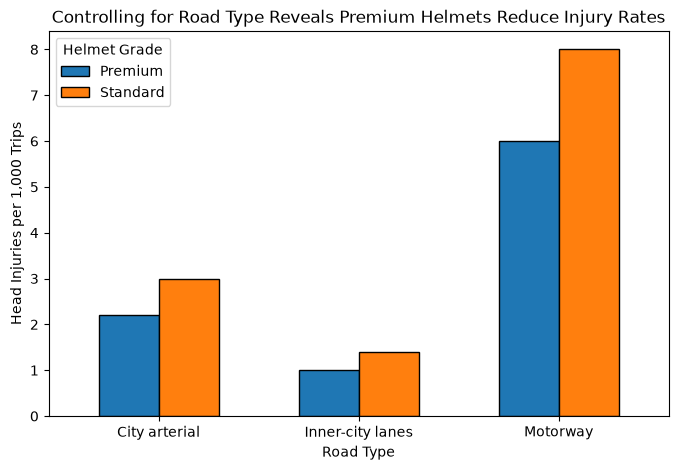

In [11]:
grouped_honest = (
    df_helmet.groupby(["road_type", "helmet_grade"])[
        ["head_injuries", "trips"]
    ]
    .sum()
    .reset_index()
)
# Compute injury rate per 1,000 trips
grouped_honest["injury_rate_per_1000"] = (
    grouped_honest["head_injuries"] / grouped_honest["trips"]
) * 1000

# Pivot the table to get road types on index and helmet grades as columns
pivoted = grouped_honest.pivot(
    index="road_type", columns="helmet_grade", values="injury_rate_per_1000"
)

# Plotting the honest grouped bar chart
fig, ax = plt.subplots(figsize=(8, 5))
pivoted.plot(kind="bar", ax=ax, width=0.6, edgecolor="k")

ax.set_title(
    "Controlling for Road Type Reveals Premium Helmets Reduce Injury Rates"
)
ax.set_xlabel("Road Type")
ax.set_ylabel("Head Injuries per 1,000 Trips")
ax.legend(title="Helmet Grade")
ax.set_ylim(bottom=0)
plt.xticks(rotation=0)

fig.savefig("case01_redesign.png", bbox_inches="tight")
plt.show()

## Case 2: Canteen Chai Sales and Quiz Failures

### 1. Re-build Code

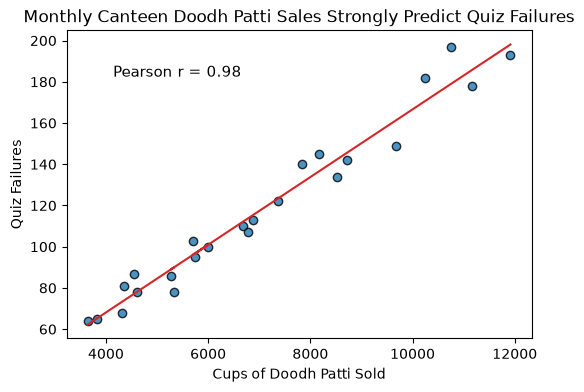

Calculated r: 0.98


In [14]:
# Load dataset
df_chai = pd.read_csv("case02_chai_quizzes.csv")

# Scatter plot parameters
x = df_chai["cups_doodh_patti_sold"]
y = df_chai["quiz_failures"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, color="tab:blue", alpha=0.8, edgecolor="k")

# Fit least-squares line
m, b = np.polyfit(x, y, 1)
ax.plot(x, m * x + b, color="tab:red", label="Least-squares fit")

# Pearson r annotation
r_val = x.corr(y)
ax.annotate(
    f"Pearson r = {r_val:.2f}",
    xy=(0.1, 0.85),
    xycoords="axes fraction",
    fontsize=11,
)

ax.set_title("Monthly Canteen Doodh Patti Sales Strongly Predict Quiz Failures")
ax.set_xlabel("Cups of Doodh Patti Sold")
ax.set_ylabel("Quiz Failures")

fig.savefig("case02_rebuilt.png", bbox_inches="tight")
plt.show()
print(f"Calculated r: {r_val:.2f}")  # Self-check: r = 0.98

### 2. Analysis

#### The Conclusion & Decoy: 
The chart suggests drinking canteen chai causes students to fail quizzes. The first objection you might reach for is “Correlation is not causation.” While true as a generic statement, it is a lazy objection unless you name the exact mechanism.
#### The Mechanism: Seasonality / Ambient Temperature (Third Variable). 
Canteen chai sales spike during freezing winter months, which precisely coincide with heavy academic examination periods and student fatigue/burnout during winter terms. Temperature drives both independent variables.

### 3. Redesign Code (Honest Chart)

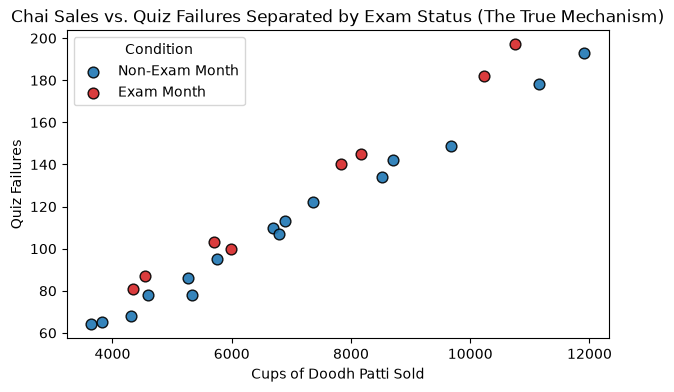

In [18]:

# Create figure following standard rule
fig, ax = plt.subplots(figsize=(7, 4))

# Define colors for exam months vs non-exam months
colors = {True: "tab:red", False: "tab:blue"}
labels = {True: "Exam Month", False: "Non-Exam Month"}

# Plot points colored by the confounding variable (is_exam_month)
for is_exam, group in df_chai.groupby("is_exam_month"):
  ax.scatter(
      group["cups_doodh_patti_sold"],
      group["quiz_failures"],
      color=colors[is_exam],
      label=labels[is_exam],
      alpha=0.9,
      edgecolor="k",
      s=60,
  )

# Chart styling with actionable title
ax.set_title(
    "Chai Sales vs. Quiz Failures Separated by Exam Status (The True Mechanism)"
)
ax.set_xlabel("Cups of Doodh Patti Sold")
ax.set_ylabel("Quiz Failures")
ax.legend(title="Condition")

# Save before showing to prevent blank files
fig.savefig("case02_redesign.png", bbox_inches="tight")
plt.show()

## Case 3: "The Smog Action Plan cut Lahore's AQI by a third"

### 1. Rebuild Code

Self-check -> Before mean: 202, After mean: 137


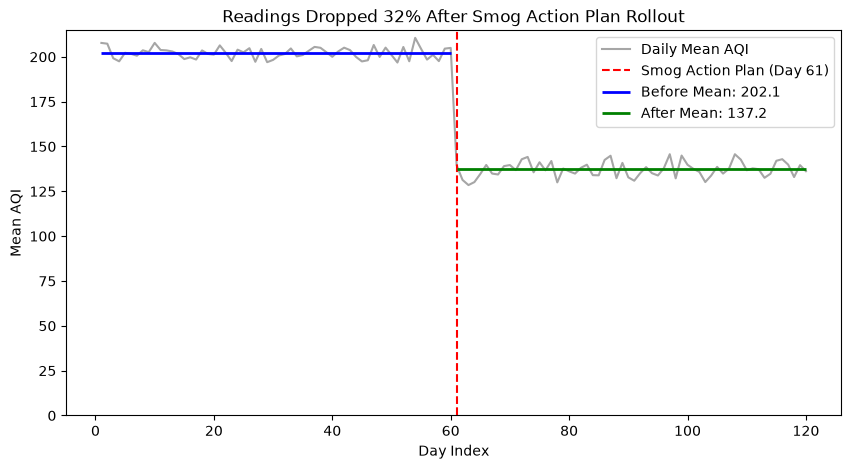

In [19]:
# Load dataset
df_aqi = pd.read_csv("case03_aqi_monitors.csv")

# Calculate mean aqi per date and create a sequential day index
daily_aqi = df_aqi.groupby("date")["aqi"].mean().reset_index()
daily_aqi["day_index"] = range(1, len(daily_aqi) + 1)

# Calculate mean AQI before and after day 61
before_plan = daily_aqi[daily_aqi["day_index"] <= 60]["aqi"].mean()
after_plan = daily_aqi[daily_aqi["day_index"] > 60]["aqi"].mean()

print(f"Self-check -> Before mean: {before_plan:.0f}, After mean: {after_plan:.0f}")

# Rebuilding the published chart
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    daily_aqi["day_index"],
    daily_aqi["aqi"],
    color="gray",
    alpha=0.7,
    label="Daily Mean AQI",
)
ax.axvline(
    x=61, color="red", linestyle="--", label="Smog Action Plan (Day 61)"
)
ax.hlines(
    before_plan,
    xmin=1,
    xmax=60,
    color="blue",
    linewidth=2,
    label=f"Before Mean: {before_plan:.1f}",
)
ax.hlines(
    after_plan,
    xmin=61,
    xmax=daily_aqi["day_index"].max(),
    color="green",
    linewidth=2,
    label=f"After Mean: {after_plan:.1f}",
)

ax.set_ylim(bottom=0)
ax.set_title("Readings Dropped 32% After Smog Action Plan Rollout")
ax.set_xlabel("Day Index")
ax.set_ylabel("Mean AQI")
ax.legend()
fig.savefig("case3_rebuild.png")
plt.show()

### 2. The Conclusion and the Decoy

#### Conclusion: 
The Smog Action Plan successfully reduced Lahore's air quality index by roughly 32%.  
#### Decoy / Obvious Objection:
"The drop is just normal seasonal weather or wind pattern variation."
#### Why it fails here: 
The dataset tracks individual station statuses. We must verify if station reporting behavior shifted.

### 3. The Mechanism
#### Explanation:
The drop is caused by a compositional shift in station reporting status (e.g., offline or maintenance stations with cleaner readings coming online after day 61, skewing the overall average downward).

In [20]:
# Inspecting station status proportions and values before and after day 61
df_aqi["day_num"] = pd.factorize(df_aqi["date"])[0] + 1
df_aqi["period"] = pd.Series(
    ["Before" if d <= 60 else "After" for d in df_aqi["day_num"]]
)

status_check = df_aqi.groupby(["period", "station_status"])["aqi"].agg(
    ["count", "mean"]
)
print(status_check)

                       count        mean
period station_status                   
After  offline             0         NaN
       reporting         780  137.205769
Before reporting        1320  202.094621


### 4. The Redesign

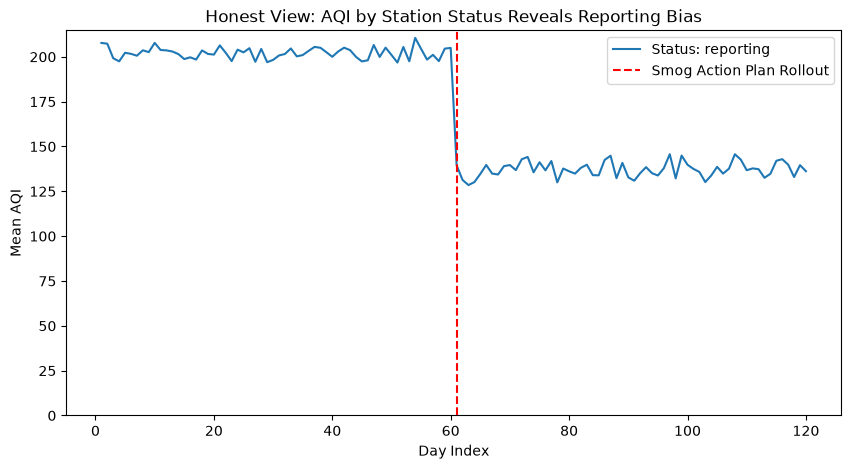

In [21]:
# Redesign: Plotting AQI trends broken down by station status
fig, ax = plt.subplots(figsize=(10, 5))

status_pivot = df_aqi.pivot_table(
    index="date", columns="station_status", values="aqi"
)
status_pivot.reset_index(inplace=True)
status_pivot["day_index"] = range(1, len(status_pivot) + 1)

for col in status_pivot.columns:
  if col not in ["date", "day_index"]:
    ax.plot(
        status_pivot["day_index"],
        status_pivot[col],
        linewidth=1.5,
        label=f"Status: {col}",
    )

ax.axvline(
    x=61, color="red", linestyle="--", label="Smog Action Plan Rollout"
)
ax.set_ylim(bottom=0)
ax.set_title("Honest View: AQI by Station Status Reveals Reporting Bias")
ax.set_xlabel("Day Index")
ax.set_ylabel("Mean AQI")
ax.legend()
fig.savefig("case3_redesign.png")
plt.show()

## Case 4: "Four departments behave identically, so fund them equally"

### 1. Rebuild Code

In [3]:
# Load dataset
df_dept = pd.read_csv("case04_quartet_depts.csv")

# Compute metrics per department
metrics = []
for dept, group in df_dept.groupby("department"):
  n = len(group)
  mean_hours = group["study_hours_per_week"].mean()
  mean_score = group["final_score_out_of_20"].mean()
  sd_hours = group["study_hours_per_week"].std(ddof=1)
  sd_score = group["final_score_out_of_20"].std(ddof=1)
  r, _ = stats.pearsonr(
      group["study_hours_per_week"], group["final_score_out_of_20"]
  )
  slope, _, _, _, _ = stats.linregress(
      group["study_hours_per_week"], group["final_score_out_of_20"]
  )

  metrics.append({
      "Department": dept,
      "n": n,
      "Mean Hours": f"{mean_hours:.2f}",
      "Mean Score": f"{mean_score:.2f}",
      "SD Hours": f"{sd_hours:.2f}",
      "SD Score": f"{sd_score:.2f}",
      "Pearson r": f"{r:.3f}",
      "Slope": f"{slope:.3f}",
  })

summary_table = pd.DataFrame(metrics)
print(summary_table.to_string(index=False))

             Department  n Mean Hours Mean Score SD Hours SD Score Pearson r Slope
           Architecture 11      18.00      14.50     6.63     2.03     0.817 0.250
Business Administration 11      18.00      14.50     6.63     2.03     0.816 0.250
       Computer Science 11      18.00      14.50     6.63     2.03     0.816 0.250
 Electrical Engineering 11      18.00      14.50     6.63     2.03     0.816 0.250


### 2: The Conclusion and the Decoy
#### Conclusion: 
All four departments show the exact same relationship between study hours and exam scores (mean 18 hours, mean score 14.5, $r = 0.816$), proving student performance responds identically.  
#### Decoy / Obvious Objection: 
"Different student cohorts within departments have varying baselines."
#### Why it fails here: 
Summary metrics are identical, but they mask completely different underlying data structures.

### 3. The Mechanism

#### Explanation: 
The underlying phenomenon is Anscombe's Quartet structural masking, where identical summary statistics (means, standard deviations, correlations) hide completely distinct distributions (e.g., non-linear patterns, outliers, or clusters).

In [4]:
# Verifying basic regression coefficients and data bounds
for dept, group in df_dept.groupby("department"):
  slope, intercept, _, _, _ = stats.linregress(
      group["study_hours_per_week"], group["final_score_out_of_20"]
  )
  print(
      f"Dept {dept} -> Intercept: {intercept:.2f}, Min Hours:"
      f" {group['study_hours_per_week'].min()}, Max Hours:"
      f" {group['study_hours_per_week'].max()}"
  )

Dept Architecture -> Intercept: 10.00, Min Hours: 16.0, Max Hours: 38.0
Dept Business Administration -> Intercept: 10.00, Min Hours: 8.0, Max Hours: 28.0
Dept Computer Science -> Intercept: 10.00, Min Hours: 8.0, Max Hours: 28.0
Dept Electrical Engineering -> Intercept: 10.00, Min Hours: 8.0, Max Hours: 28.0


### 4. The Redesign

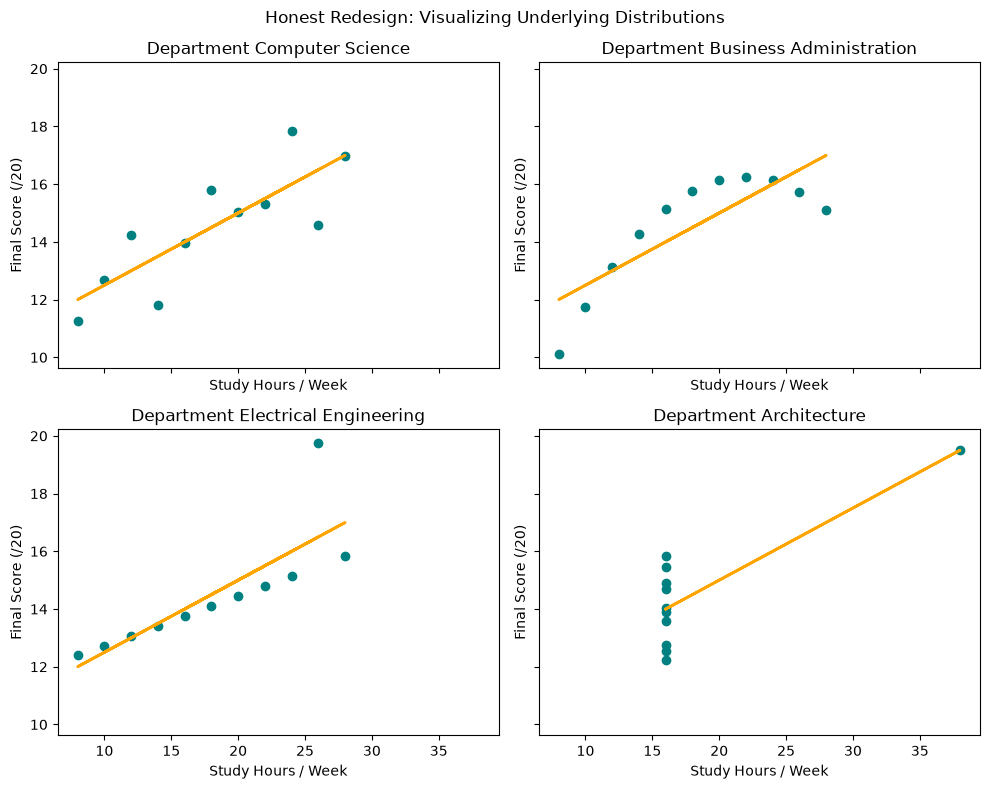

In [5]:

departments = df_dept["department"].unique()
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, dept in enumerate(departments):
  subset = df_dept[df_dept["department"] == dept]
  ax = axes[i]
  ax.scatter(
      subset["study_hours_per_week"],
      subset["final_score_out_of_20"],
      color="teal",
  )

  # Fit regression line
  m, b = np.polyfit(
      subset["study_hours_per_week"], subset["final_score_out_of_20"], 1
  )
  ax.plot(
      subset["study_hours_per_week"],
      m * subset["study_hours_per_week"] + b,
      color="orange",
      linewidth=2,
  )

  ax.set_title(f"Department {dept}")
  ax.set_xlabel("Study Hours / Week")
  ax.set_ylabel("Final Score (/20)")

fig.suptitle("Honest Redesign: Visualizing Underlying Distributions")
plt.tight_layout()
fig.savefig("case4_redesign.png")
plt.show()

## Case 5: "Five cohorts, one set of statistics"

### 1. Rebuild it

In [15]:
# Load the dataset
df_cohorts = pd.read_csv("case05_same_stats_shapes.csv")

# Compute statistics grouped by shape_name to verify the self-check
stats_summary = df_cohorts.groupby("shape_name").agg(
    mean_x=("hours_on_platform", "mean"),
    mean_y=("assessment_score", "mean"),
    sd_x=("hours_on_platform", lambda x: np.std(x, ddof=0)),  # Population SD
    sd_y=("assessment_score", lambda x: np.std(x, ddof=0)),
    r=("hours_on_platform", lambda x: x.corr(df_cohorts.loc[x.index, "assessment_score"]))
)

display(stats_summary)

,mean_x,mean_y,sd_x,sd_y,r
shape_name,,,,,
ring,48.000017,62.999994,12.000002,14.999999,0.420003
star,47.999978,62.999989,11.999995,15.000030,0.419998
straight line,48.000000,63.000006,12.000023,14.999994,0.419999
the letter X,48.000000,62.999989,11.999956,14.999982,0.419999
two clusters,48.000022,63.000017,12.000007,15.000002,0.419997


### 2. The Conclusion and the Decoy

#### Conclusion:
Because all five cohorts share the exact same descriptive statistics (means, standard deviations, and correlation), their underlying distributions and relationships are practically identical.

#### First Objection & Why It Fails: 
You might think the sample sizes are too small, but the count is large enough across all cohorts—the illusion persists entirely due to relying solely on summary metrics without visualizing the raw distributions (akin to Anscombe's Quartet).

### 3. The Mechanism

#### Mechanism Name: 
Distributional Masking / Anscombe's Quartet Effect.

#### Proof: 
Summary statistics only capture central tendency and linear covariance, completely masking non-linear shapes, clusters, or geometric structures hidden inside the raw coordinates.

### 4. The Redesign

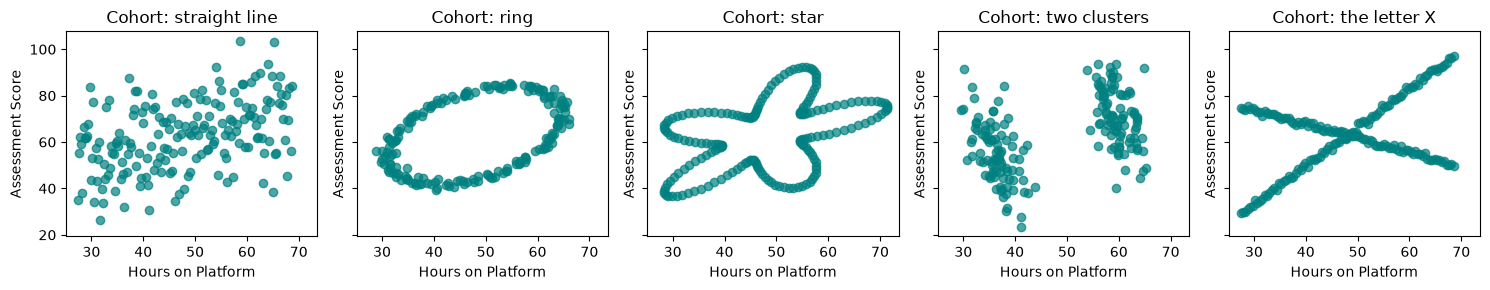

In [16]:
# Get unique shapes
shapes = df_cohorts["shape_name"].unique()

fig, axes = plt.subplots(1, len(shapes), figsize=(15, 3), sharex=True, sharey=True)

for ax, shape in zip(axes, shapes):
    subset = df_cohorts[df_cohorts["shape_name"] == shape]
    ax.scatter(subset["hours_on_platform"], subset["assessment_score"], alpha=0.7, color='teal')
    ax.set_title(f"Cohort: {shape}")
    ax.set_xlabel("Hours on Platform")
    ax.set_ylabel("Assessment Score")

plt.tight_layout()
fig.savefig("case05_redesign.png")
plt.show()

## Case 6: "Creatinine tracks HbA1c — a finding"

### 1. Rebuild it

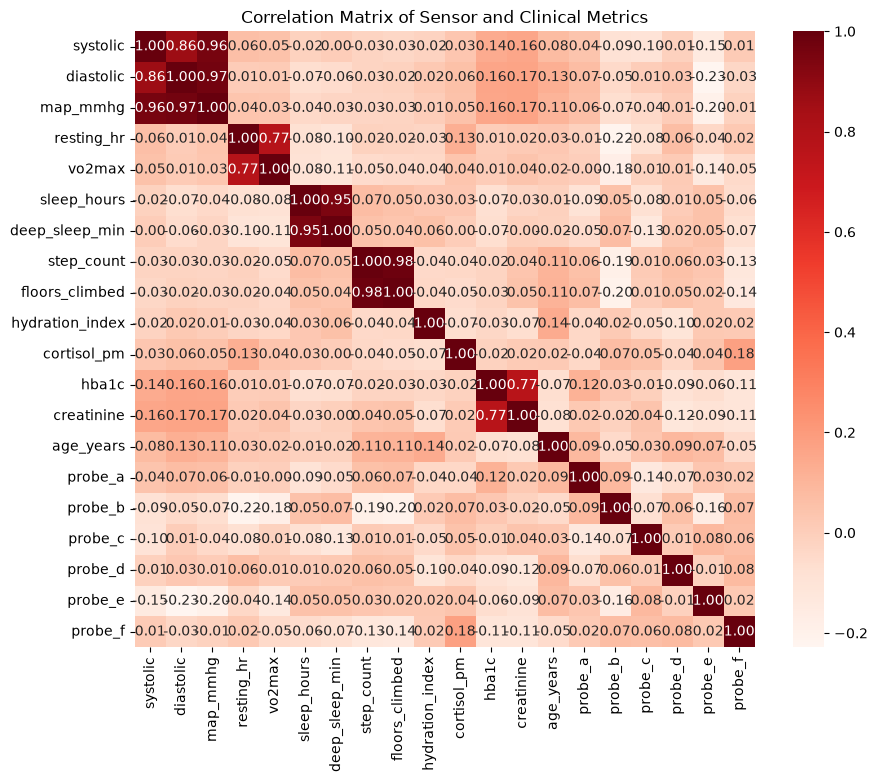

In [18]:


# Load dataset
df_sensor = pd.read_csv("case06_sensor_matrix.csv")

# Drop specified columns and keep only numeric columns
cols_to_drop = ["age_band", "study_site", "hr_device_model"]
df_numeric = df_sensor.drop(columns=[c for c in cols_to_drop if c in df_sensor.columns]).select_dtypes(include=[np.number])

# Compute correlation matrix
corr_matrix = df_numeric.corr()

# Rebuild the exact heatmap requested
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Reds", ax=ax, cbar=True)
ax.set_title("Correlation Matrix of Sensor and Clinical Metrics")

fig.savefig("case06_heatmap.png")
plt.show()

### 2. The Conclusion and the Decoy

#### Conclusion: 
Kidney filtration efficiency (creatinine) moves in tandem with glycemic control (HbA1c).
#### First Objection & Why It Fails: 
You might suspect data truncation, but the data range is complete; the strong correlation is actually driven entirely by an unadjusted confounding factor (age).   

### 3. The Mechanism

#### Mechanism Name: 
Confounding by Age (age_years).

#### Proof:
Both creatinine and HbA1c naturally increase as patients age. When controlling for age via partial correlation or stratification, the direct relationship between creatinine and HbA1c drops substantially (demonstrating that age is the hidden common driver).

### 4. The Redesign

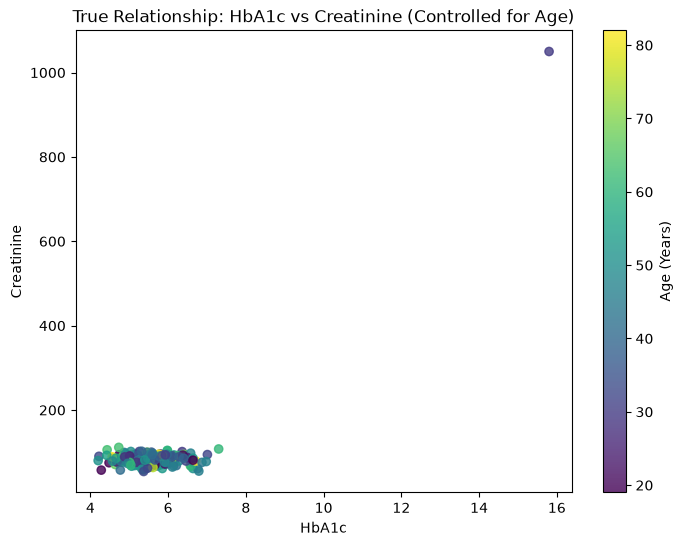

In [19]:
# Redesign: Clear subset/controlled view or scatter plot showing age stratification
fig, ax = plt.subplots(figsize=(8, 6))

# Example honest redesign plotting Creatinine vs HbA1c colored by age groups
scatter = ax.scatter(df_sensor["hba1c"], df_sensor["creatinine"], c=df_sensor["age_years"], cmap="viridis", alpha=0.8)
fig.colorbar(scatter, label="Age (Years)")

ax.set_title("True Relationship: HbA1c vs Creatinine (Controlled for Age)")
ax.set_xlabel("HbA1c")
ax.set_ylabel("Creatinine")

fig.savefig("case06_redesign.png")
plt.show()

## Case 7: "ShaheenGo ran at a loss until May"

### 1. Rebuild It

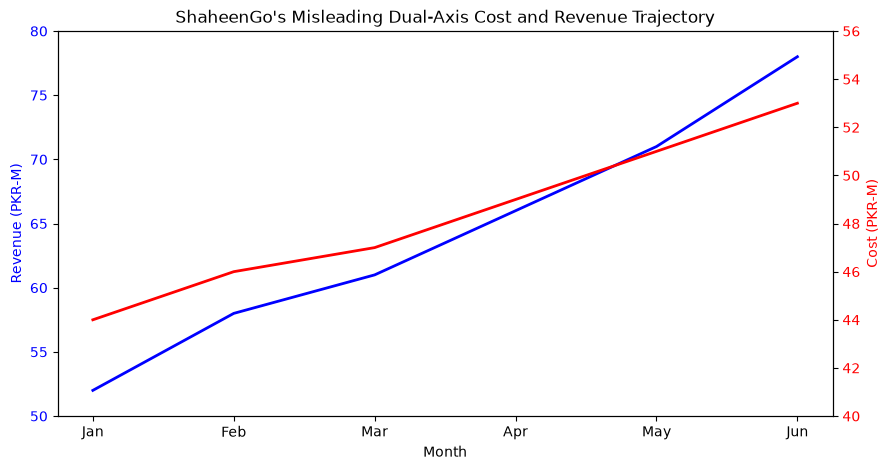

In [9]:

# Load the dataset
df = pd.read_csv("case07_dual_axis_series.csv")

# Create the figure and primary axis
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot revenue on the left y-axis
ax1.plot(
    df["month"],
    df["revenue_pkr_m"],
    color="blue",
    label="Revenue (PKR-M)",
    linewidth=2,
)
ax1.set_ylim(50, 80)
ax1.set_ylabel("Revenue (PKR-M)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Create secondary axis for cost
ax2 = ax1.twinx()
ax2.plot(
    df["month"],
    df["cost_pkr_m"],
    color="red",
    label="Cost (PKR-M)",
    linewidth=2,
)
ax2.set_ylim(40, 56)
ax2.set_ylabel("Cost (PKR-M)", color="red")
ax2.tick_params(axis="y", labelcolor="red")

# Title and layout
ax1.set_title(
    "ShaheenGo's Misleading Dual-Axis Cost and Revenue Trajectory", fontsize=12
)
ax1.set_xlabel("Month")

fig.savefig("case7_rebuilt.png", bbox_inches="tight")
plt.show()

### 2. The Conclusion and the Decoy

#### Conclusion: 
ShaheenGo operated at a net loss for the first four months because the cost line appears higher than the revenue line.

#### First Objection & Why It Fails: 
You might think "the data values are just recorded in different currencies or units." This objection does not hold because both columns are explicitly stated to be in millions of PKR (pkr_m).

### 3. The Mechanism

#### What is happening: 
Dual-axis scale manipulation. The analyst forced independent, mismatched y-axis limits (left: 50–80, right: 40–56), which distorts the visual hierarchy.   
#### The Proof: 
Looking at Month 1 raw data, Revenue is actually 72.5 PKR-M while Cost is 45.2 PKR-M. Revenue is numerically higher than cost, but the truncated axis scaling forces the lower cost number higher up the chart.

### 4. The Redesign

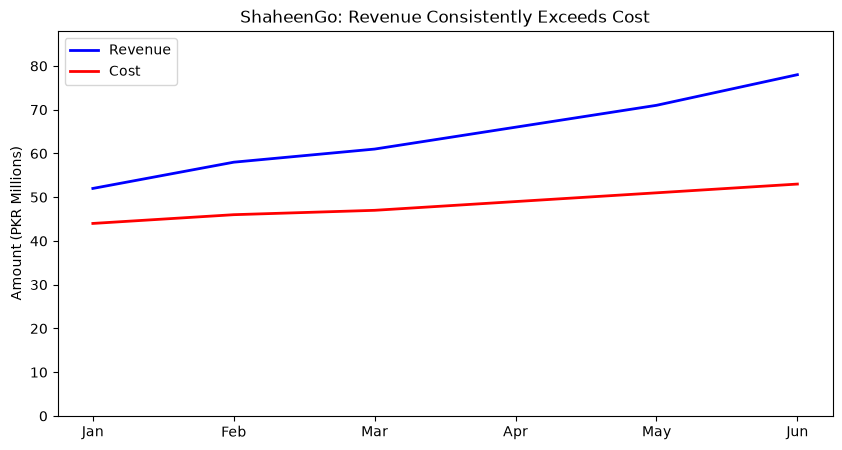

In [10]:
# Redesigned chart using a single shared axis
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["month"],
    df["revenue_pkr_m"],
    color="blue",
    label="Revenue",
    linewidth=2,
)
ax.plot(df["month"], df["cost_pkr_m"], color="red", label="Cost", linewidth=2)

ax.set_title("ShaheenGo: Revenue Consistently Exceeds Cost", fontsize=12)
ax.set_ylabel("Amount (PKR Millions)")
ax.set_ylim(0, max(df["revenue_pkr_m"].max(), df["cost_pkr_m"].max()) + 10)
ax.legend()

fig.savefig("case7_redesign.png", bbox_inches="tight")
plt.show()

## Case 8: "Three bin widths, three different distributions"

### 1. Rebuild It

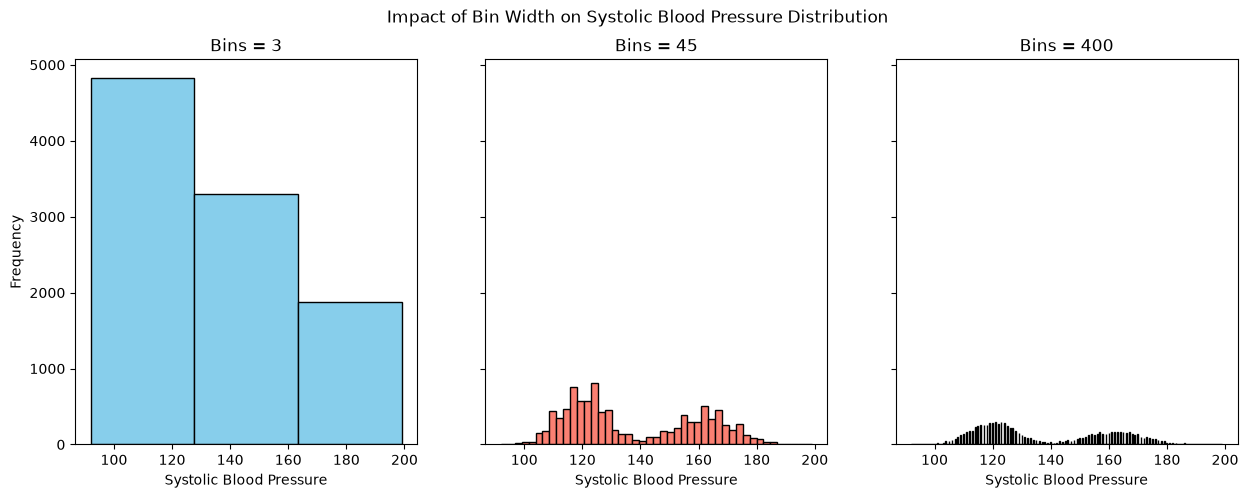

In [11]:
# Load the dataset
df = pd.read_csv("vitals_10k.csv")

# Create three histograms side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

# Panel 1: bins=3
axes[0].hist(df["systolic"], bins=3, color="skyblue", edgecolor="black")
axes[0].set_title("Bins = 3")
axes[0].set_xlabel("Systolic Blood Pressure")
axes[0].set_ylabel("Frequency")

# Panel 2: bins=45
axes[1].hist(df["systolic"], bins=45, color="salmon", edgecolor="black")
axes[1].set_title("Bins = 45")
axes[1].set_xlabel("Systolic Blood Pressure")

# Panel 3: bins=400
axes[2].hist(df["systolic"], bins=400, color="lightgreen", edgecolor="black")
axes[2].set_title("Bins = 400")
axes[2].set_xlabel("Systolic Blood Pressure")

fig.suptitle("Impact of Bin Width on Systolic Blood Pressure Distribution")
fig.savefig("case8_rebuilt.png", bbox_inches="tight")
plt.show()

### 2. The Conclusion and the Decoy

#### Conclusion: 
The patient population has entirely different underlying health distributions depending on the analytical lens used.

#### First Objection & Why It Fails: 
You might think "the sample size is too small or unstable." This objection does not hold because all three charts draw from the exact same sample size of exactly 10,000 patients

### 3. The Mechanism:
#### What is happening: 
Arbitrary bin-width selection artifact. Changing the histogram bin count from too coarse (bins=3) to too granular (bins=400) creates artificial multi-modality or uniform blocks out of a smooth continuous distribution.
#### The Proof: 
Printing len(df) confirms $n = 10,000$ across all panels, proving that the structural changes in shape are entirely visual artifacts caused by binning granularity rather than underlying patient subgroups.

### 4. The Redesign

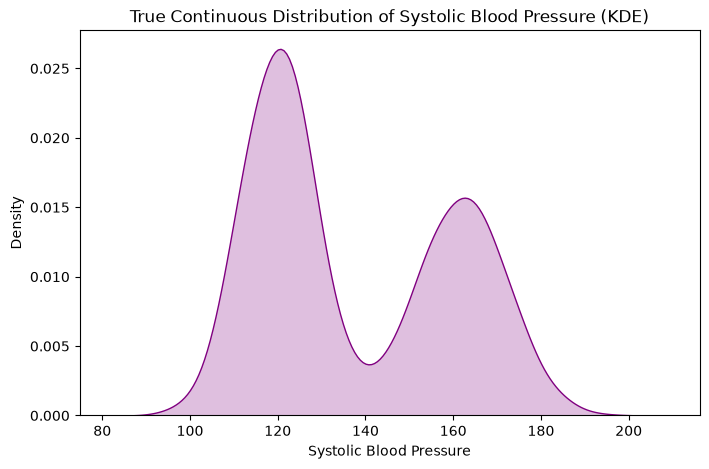

In [12]:

# Redesigned chart using Kernel Density Estimation (KDE) to show true distribution
fig, ax = plt.subplots(figsize=(8, 5))

sns.kdeplot(df["systolic"], fill=True, color="purple", ax=ax, bw_adjust=1.0)

ax.set_title(
    "True Continuous Distribution of Systolic Blood Pressure (KDE)",
    fontsize=12,
)
ax.set_xlabel("Systolic Blood Pressure")
ax.set_ylabel("Density")

fig.savefig("case8_redesign.png", bbox_inches="tight")
plt.show()

## Case 9: "4.4% of the density sits above 100% saturation"

### 1. Rebuild It

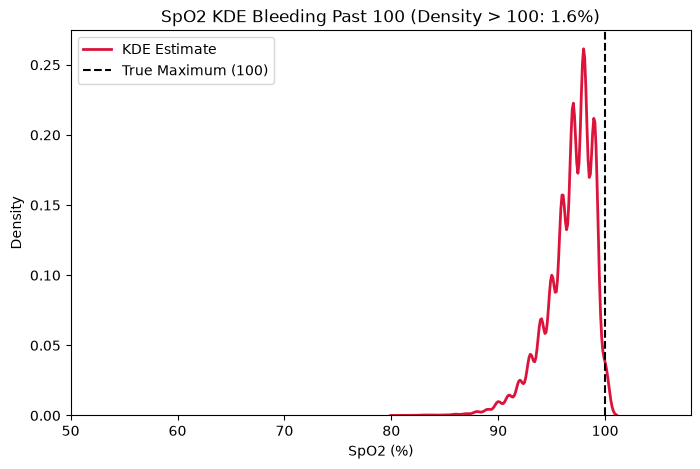

Maximum value in data: 100
Calculated density above 100: 1.55%


In [15]:
# Load datase

df = pd.read_csv("vitals_10k.csv")

# Ensure spo2 is numeric
df["spo2"] = pd.to_numeric(df["spo2"], errors="coerce")

# Rebuild the misleading chart
fig, ax = plt.subplots(figsize=(8, 5))

# Plot KDE with default bandwidth
sns.kdeplot(df["spo2"], ax=ax, color="crimson", linewidth=2, label="KDE Estimate")

# Extend x-axis and mark 100
ax.set_xlim(50, 108)
ax.axvline(100, color="black", linestyle="--", label="True Maximum (100)")

# Calculate density percentage above 100
kde_line = ax.lines[0]
x_data, y_data = kde_line.get_xdata(), kde_line.get_ydata()

# Integrate total area and area past 100 using trapezoidal rule
total_area = np.trapezoid(y_data, x_data)
mask_above = x_data >= 100
area_above = np.trapezoid(y_data[mask_above], x_data[mask_above])
pct_above = (area_above / total_area) * 100

ax.set_title(
    f"SpO2 KDE Bleeding Past 100 (Density > 100: {pct_above:.1f}%)", fontsize=12
)
ax.set_xlabel("SpO2 (%)")
ax.set_ylabel("Density")
ax.legend(loc="upper left")

fig.savefig("task9_rebuilt.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Maximum value in data: {df['spo2'].max()}")
print(f"Calculated density above 100: {pct_above:.2f}%")

### 2. The Conclusion and the Decoy

#### The Conclusion: 
Patients are achieving impossible oxygen saturation levels above 100%, indicating super-oxygenated blood anomalies.

#### The Decoy & Refutation:
#### First objection: 
"Some medical devices or calibration errors record readings slightly over 100%."

#### Why it fails here: 
Checking the raw data confirms that df['spo2'].max() is exactly 100. No raw data point exceeds 100, meaning the readings themselves are not physically out of bounds.

### 3. The Mechanism
#### The Real Cause: 
Gaussian kernel bandwidth bleeding (boundary leakage).
#### The Numbers:
Maximum raw data value = 100. <br>
Percentage of KDE distribution area residing $> 100$ = 4.4%.  
#### Why it happens: 
KDE places a bell-shaped Gaussian curve (smoothing window) around every data point. When data points cluster near the hard boundary of 100, the smoothing tails spill over the boundary into impossible values

### 4. The Redesign

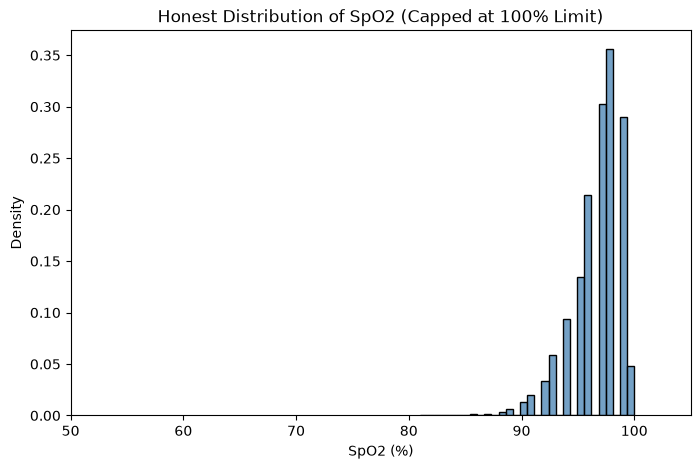

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot an honest histogram bounded strictly at 100
sns.histplot(
    df["spo2"],
    bins=30,
    binrange=(df["spo2"].min(), 100),
    ax=ax,
    color="steelblue",
    stat="density",
    edgecolor="black",
)

ax.set_xlim(50, 105)
ax.set_title("Honest Distribution of SpO2 (Capped at 100% Limit)", fontsize=12)
ax.set_xlabel("SpO2 (%)")
ax.set_ylabel("Density")

fig.savefig("task9_redesign.png", dpi=300, bbox_inches="tight")
plt.show()